# Portifólio — 2º bimestre, atividade 1

Implementação manual de filtros espaciais de média, mediana, moda e máxima. A imagem `moon` do `skimage` já está em escala de cinza. As operações de vizinhança são implementadas em Python/NumPy; nenhuma função de filtragem do OpenCV é utilizada.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from skimage import data

imagem_original = data.moon()
print(f"Imagem em escala de cinza: {imagem_original.shape}, tipo: {imagem_original.dtype}")


## Convolução manual

A função abaixo percorre os pixels e os elementos do kernel, invertendo o kernel como define a convolução. Nas bordas, replica os pixels mais próximos (`padding='edge'`). O filtro da média é calculado com essa função. Mediana, moda e máxima são filtros não lineares: cada um calcula diretamente uma estatística da janela local.


In [2]:
def convolucao_manual(imagem, kernel):
    """Calcula a convolução 2D sem usar funções de filtragem do OpenCV."""
    imagem = np.asarray(imagem)
    kernel = np.asarray(kernel, dtype=np.float64)

    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (matriz 2D).")
    if kernel.ndim != 2 or kernel.shape[0] != kernel.shape[1]:
        raise ValueError("O kernel deve ser uma matriz quadrada.")
    if kernel.shape[0] % 2 == 0:
        raise ValueError("O lado do kernel deve ser ímpar.")

    altura, largura = imagem.shape
    lado = kernel.shape[0]
    raio = lado // 2
    imagem_preenchida = np.pad(
        imagem, ((raio, raio), (raio, raio)), mode="edge"
    )
    resultado = np.zeros((altura, largura), dtype=np.float64)

    for y in range(altura):
        for x in range(largura):
            acumulado = 0.0
            for ky in range(lado):
                for kx in range(lado):
                    # A inversão de 180 graus distingue convolução de correlação.
                    acumulado += (
                        float(imagem_preenchida[y + ky, x + kx])
                        * kernel[lado - 1 - ky, lado - 1 - kx]
                    )
            resultado[y, x] = acumulado

    return resultado


def _preparar_janelas(imagem, tamanho):
    imagem = np.asarray(imagem)
    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (matriz 2D).")
    if not isinstance(tamanho, (int, np.integer)) or tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser um inteiro positivo ímpar.")

    raio = tamanho // 2
    preenchida = np.pad(
        imagem, ((raio, raio), (raio, raio)), mode="edge"
    )
    return imagem, preenchida, raio


def _restaurar_tipo(resultado, imagem):
    if np.issubdtype(imagem.dtype, np.integer):
        limites = np.iinfo(imagem.dtype)
        resultado = np.clip(np.rint(resultado), limites.min, limites.max)
    return resultado.astype(imagem.dtype)


## Filtros

O tamanho padrão da vizinhança é `5 × 5` e pode ser alterado passando outro tamanho ímpar. Para a moda, se houver empate, o valor do pixel central vence quando está entre as modas; caso contrário, vence o menor valor.


In [3]:
def filtro_media(imagem, tamanho=5):
    """Aplica a média local com um kernel uniforme e convolução manual."""
    imagem = np.asarray(imagem)
    _preparar_janelas(imagem, tamanho)  # valida a imagem e o tamanho
    kernel = np.ones((tamanho, tamanho), dtype=np.float64) / (tamanho * tamanho)
    resultado = convolucao_manual(imagem, kernel)
    return _restaurar_tipo(resultado, imagem)


def filtro_mediana(imagem, tamanho=5):
    """Substitui cada pixel pela mediana da sua vizinhança."""
    imagem, preenchida, raio = _preparar_janelas(imagem, tamanho)
    resultado = np.empty_like(imagem)
    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            valores_ordenados = sorted(janela.ravel().tolist())
            resultado[y, x] = valores_ordenados[len(valores_ordenados) // 2]
    return resultado


def filtro_moda(imagem, tamanho=5):
    """Substitui cada pixel pela moda da sua vizinhança."""
    imagem, preenchida, raio = _preparar_janelas(imagem, tamanho)
    resultado = np.empty_like(imagem)
    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            contagens = Counter(janela.ravel().tolist())
            frequencia_maxima = max(contagens.values())
            modas = [valor for valor, frequencia in contagens.items()
                     if frequencia == frequencia_maxima]
            centro = imagem[y, x].item()
            resultado[y, x] = centro if centro in modas else min(modas)
    return resultado


def filtro_maxima(imagem, tamanho=5):
    """Substitui cada pixel pelo maior valor da sua vizinhança."""
    imagem, preenchida, raio = _preparar_janelas(imagem, tamanho)
    resultado = np.empty_like(imagem)
    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            janela = preenchida[y:y + tamanho, x:x + tamanho]
            resultado[y, x] = max(janela.ravel().tolist())
    return resultado


## Comparação visual

Cada linha compara a imagem original com o resultado de um filtro. As quatro comparações compartilham a mesma escala de intensidade para facilitar a leitura.


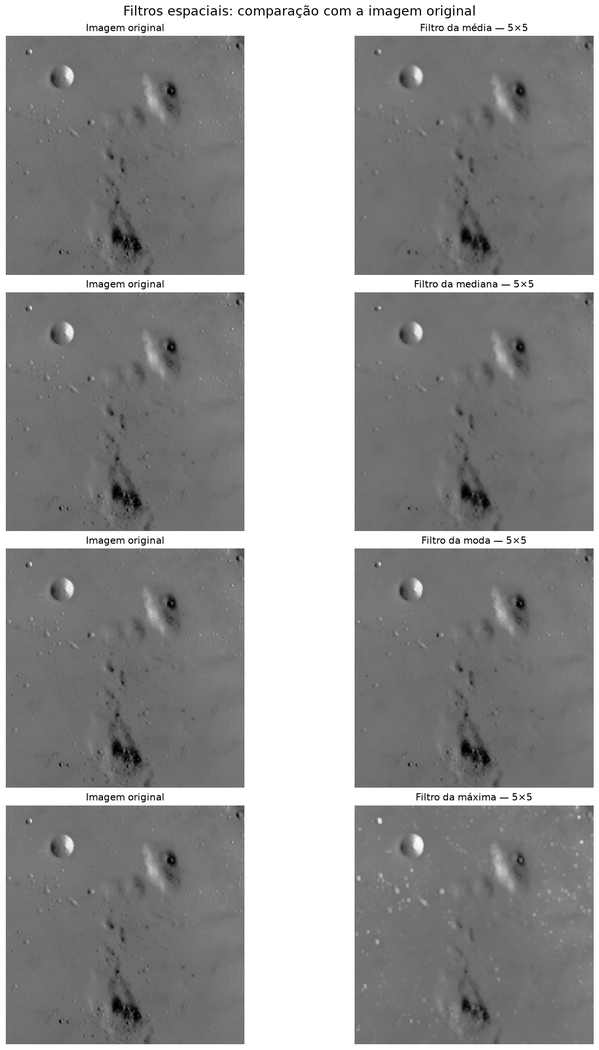

In [4]:
tamanho_janela = 5
resultados = [
    ("Média", filtro_media(imagem_original, tamanho_janela)),
    ("Mediana", filtro_mediana(imagem_original, tamanho_janela)),
    ("Moda", filtro_moda(imagem_original, tamanho_janela)),
    ("Máxima", filtro_maxima(imagem_original, tamanho_janela)),
]

fig, eixos = plt.subplots(4, 2, figsize=(12, 18), constrained_layout=True)
for linha, (nome, imagem_filtrada) in enumerate(resultados):
    eixos[linha, 0].imshow(imagem_original, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 0].set_title("Imagem original")
    eixos[linha, 1].imshow(imagem_filtrada, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 1].set_title(f"Filtro da {nome.lower()} — {tamanho_janela}×{tamanho_janela}")
    for eixo in eixos[linha]:
        eixo.axis("off")

fig.suptitle("Filtros espaciais: comparação com a imagem original", fontsize=16)
plt.show()


## Observações

- **Média:** suaviza a imagem ao calcular a média da vizinhança.
- **Mediana:** usa o valor central após ordenar a janela; costuma preservar melhor as bordas que a média.
- **Moda:** escolhe o valor mais frequente na janela, com desempate determinístico.
- **Máxima:** seleciona o maior valor local e expande regiões claras.

A função `convolucao_manual` é usada pelo filtro da média. Os outros três são não lineares e, por isso, são calculados diretamente sobre cada janela.
